In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install mne
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 138.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 119.0 MB/s eta 0:00:00


In [ ]:
import mne
import matplotlib.pyplot as plt

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy import signal
from sklearn.model_selection import train_test_split
import json
from pathlib import Path
from typing import List, Tuple, Dict
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# ============================================================================
# SECTION 1: DATA INGESTION AND PREPROCESSING
# ============================================================================

In [ ]:
class CHBMITDataProcessor:
    """Handles downloading, reading, and windowing CHB-MIT EEG data"""

    def __init__(self, data_dir: str, window_size: int = 10, stride: int = 20,
                 sampling_rate: int = 256, patients: List[str] = None):#256 Hz(256 samples per second,window_size:how long each segment is,stride:how far you slide the window each time)
        """
        Args:
            data_dir: Path to CHB-MIT data directory
            window_size: Window size in seconds (default: 10s)
            stride: Stride in seconds (default: 5s)
            sampling_rate: EEG sampling rate (default: 256 Hz)
            patients: List of patient IDs to process (e.g., ['chb01', 'chb02'])
        """

        self.data_dir = Path(data_dir)
        self.window_size = window_size #how long each EEG segment is in seconds (10 s).
        self.stride = stride #how far you slide the window in seconds (5 s).
        self.sampling_rate = sampling_rate #Hz, 256 samples per second (CHB-MIT default).
        self.window_samples = window_size * sampling_rate #Example:10s *256Hz = 2560 samples per window
        self.stride_samples = stride * sampling_rate
        self.patients = patients or ['chb01', 'chb02', 'chb03', 'chb04']

    def _get_patient_data_path(self, patient_id: str) -> Path:
        """Helper to construct the full path to a patient's data directory based on wget structure."""
        return self.data_dir / patient_id / "physionet.org" / "files" / "chbmit" / "1.0.0" / patient_id

    def load_seizure_annotations(self, patient_id: str) -> Dict:
        """Load seizure annotations from summary file"""
        patient_specific_path = self._get_patient_data_path(patient_id)
        summary_file = patient_specific_path / f"{patient_id}-summary.txt"

        if not os.path.exists(summary_file): # Using os.path.exists
            return {}

        seizure_info = {}

        with open(summary_file, 'r') as f:
            lines = f.readlines()

        current_file = None
        for line in lines:
            line = line.strip()
            if 'File Name:' in line:
                current_file = line.split(':')[1].strip()
                seizure_info[current_file] = []
            elif 'Number of Seizures' in line and current_file:
                num_seizures = int(line.split(':')[1].strip())
                if num_seizures == 0:
                    seizure_info[current_file] = []
            elif 'Seizure Start Time' in line and current_file:
                start = int(line.split(':')[1].strip().split()[0])
                seizure_info[current_file].append({'start': start})
            elif 'Seizure End Time' in line and current_file:
                end = int(line.split(':')[1].strip().split()[0])
                if seizure_info[current_file]:
                    seizure_info[current_file][-1]['end'] = end

        return seizure_info#stores the info about the seizures from the summary files(given in the dataset)

    def preprocess_eeg(self, raw_data: np.ndarray) -> np.ndarray:
        """Apply bandpass filter and normalization"""
        # Bandpass filter 0.5-40 Hz,signal.butter → designs a Butterworth filter,4->order of filter(4th order means sharp but stable),output = 'sos'(second-order-sections)
        sos = signal.butter(4, [0.5, 40], btype='band',
                           fs=self.sampling_rate, output='sos')
        filtered = signal.sosfiltfilt(sos, raw_data, axis=1) #sosfiltfilt = forward + backward filtering

        # Normalize per channel (z-score)#z-score normalization
        mean = filtered.mean(axis=1, keepdims=True)
        std = filtered.std(axis=1, keepdims=True) + 1e-8
        normalized = (filtered - mean) / std

        return normalized

    def create_windows(self, eeg_data: np.ndarray, seizure_times: List[Dict],
                      patient_id: str, file_name: str) -> pd.DataFrame:
        """Segment EEG into overlapping windows with labels"""
        n_channels, n_samples = eeg_data.shape
        windows = []

        # Calculate number of windows
        n_windows = (n_samples - self.window_samples) // self.stride_samples + 1

        for i in range(n_windows):
            start_sample = i * self.stride_samples
            end_sample = start_sample + self.window_samples

            if end_sample > n_samples:
                break

            # Extract window
            window_data = eeg_data[:, start_sample:end_sample]

            # Convert to time
            start_time = start_sample / self.sampling_rate
            end_time = end_sample / self.sampling_rate

            # Check if window overlaps with any seizure
            is_seizure = False
            for seizure in seizure_times:
                if not (end_time <= seizure['start'] or start_time >= seizure['end']):
                    is_seizure = True
                    break

            windows.append({
                'patient_id': patient_id,
                'file_name': file_name,
                'window_idx': i,
                'start_time': start_time,
                'end_time': end_time,
                'label': 1 if is_seizure else 0,
                'data': window_data
            })

        return pd.DataFrame(windows)

    def process_dataset(self) -> pd.DataFrame:
        """Process all patients and create window index"""
        all_windows = []

        for patient_id in self.patients:
            print(f"Processing {patient_id}...")
            patient_data_path = self._get_patient_data_path(patient_id)

            # Debugging print statement
            print(f"  DEBUG: Checking path '{patient_data_path}'")

            if not os.path.exists(patient_data_path): # Changed from patient_data_path.exists()
                print(f"Warning: {patient_data_path} directory not found, skipping...")
                continue

            # Load seizure annotations
            seizure_annotations = self.load_seizure_annotations(patient_id)

            # Process each .edf file
            edf_files = sorted(patient_data_path.glob('*.edf'))

            for edf_file in edf_files:  # Limit files for mid-project
                file_name = edf_file.name
                print(f"  Processing {file_name}...")

                try:
                    # Read EEG data
                    raw = mne.io.read_raw_edf(edf_file, preload=True, verbose=False)
                    data = raw.get_data()

                    # Ensure 23 channels (pad or truncate if needed)
                    if data.shape[0] < 23:
                        padding = np.zeros((23 - data.shape[0], data.shape[1]))
                        data = np.vstack([data, padding])
                    elif data.shape[0] > 23:
                        data = data[:23, :]

                    # Preprocess
                    data = self.preprocess_eeg(data)

                    # Get seizure times for this file
                    seizure_times = seizure_annotations.get(file_name, [])

                    # Create windows
                    windows_df = self.create_windows(data, seizure_times,
                                                     patient_id, file_name)
                    all_windows.append(windows_df)

                except Exception as e:
                    print(f"Error processing {file_name}: {e}")
                    continue

        # Combine all windows
        df_windows = pd.concat(all_windows, ignore_index=True)

        print(f"\nTotal windows created: {len(df_windows)}")
        print(f"Seizure windows: {df_windows['label'].sum()}")
        print(f"Non-seizure windows: {(df_windows['label'] == 0).sum()}")

        return df_windows

In [ ]:
# ============================================================================
# SECTION 2: SELF-SUPERVISED CONTRASTIVE LEARNING
# ============================================================================

In [ ]:
class EEGAugmentation: #we create two different “views” of the same window
    """Data augmentation for EEG signals"""#SimCLR needs two different augmented versions of the same window->these become positive pairs

    @staticmethod
    def add_noise(x: torch.Tensor, noise_level: float = 0.1) -> torch.Tensor:
        """Add Gaussian noise"""#noise_level=0.1
        noise = torch.randn_like(x) * noise_level
        return x + noise

    @staticmethod
    def scale(x: torch.Tensor, scale_range: Tuple[float, float] = (0.9, 1.1)) -> torch.Tensor:
        """Random scaling"""
        scale_factor = torch.FloatTensor(1).uniform_(*scale_range).item()
        return x * scale_factor

    @staticmethod
    def time_shift(x: torch.Tensor, max_shift: int = 128) -> torch.Tensor:
        """Random time shift (circular)"""#randomly shifts signal left/right,circular shift->no loss of samples
        shift = np.random.randint(-max_shift, max_shift)
        return torch.roll(x, shift, dims=-1)

    @staticmethod
    def augment(x: torch.Tensor) -> torch.Tensor:
        """Apply random augmentations"""
        x = EEGAugmentation.add_noise(x, noise_level=0.05)
        x = EEGAugmentation.scale(x, scale_range=(0.95, 1.05))
        if np.random.rand() > 0.5:#50 percent chance apply time shift
            x = EEGAugmentation.time_shift(x, max_shift=64)
        return x


class EEGDataset(Dataset):
    """Dataset for contrastive learning"""

    def __init__(self, windows_df: pd.DataFrame, augment: bool = True):
        self.windows_df = windows_df
        self.augment = augment

    def __len__(self):
        return len(self.windows_df)

    def __getitem__(self, idx):
        row = self.windows_df.iloc[idx]#load one EEG Window->convert to tensor->Shape:23 channels*2560 samples
        x = torch.FloatTensor(row['data'])  # Shape: (23, 2560)
        label = torch.LongTensor([row['label']])

        if self.augment:
            # Create two augmented views
            x1 = EEGAugmentation.augment(x)#x1 = augmented version 1
            x2 = EEGAugmentation.augment(x)#x2 = augmented version 2
            return x1, x2, label, idx#label is not used for training,only saved
        else:
            return x, label, idx


class EEGEncoder(nn.Module):
    """1D CNN encoder for EEG signals"""

    def __init__(self, n_channels: int = 23, embedding_dim: int = 128):
        super().__init__()

        self.encoder = nn.Sequential(
            # Conv block 1
            nn.Conv1d(n_channels, 64, kernel_size=7, stride=2, padding=3),#23 channels->64 feature maps,reduces time resolution by factor 4(stride=2,mmaxpool=2)
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            # Conv block 2
            nn.Conv1d(64, 128, kernel_size=5, stride=2, padding=2),#(64 channels->128 feature maps,reduces time resolution by factor 4(stride=2,mmaxpool=2)
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),

            # Conv block 3
            nn.Conv1d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)#final output->shape becomes(batch,256,1),AdaptiveAvgPool->compress time dimension to 1
        )
            #We use AdaptiveAvgPool(1d) compresses any input length to 1 by averging all values along the time dimension,maxpool might losse the fine-grained temporal info. INput(batch,256,32)->output(batch,256,1)

        self.embedding_layer = nn.Linear(256, embedding_dim)

    def forward(self, x):
        # x shape: (batch, channels, time_steps)
        features = self.encoder(x)  # (batch, 256, 1)#passes input through the 1D CNN+AdaptiveAvgPool1d
        features = features.squeeze(-1)  # (batch, 256)
        embeddings = self.embedding_layer(features)  # (batch, embedding_dim) #Fully connected layer converts 256->embedding_dim(default 128)
        return embeddings


class ProjectionHead(nn.Module):
  #
    """MLP projection head for contrastive learning"""

    def __init__(self, embedding_dim: int = 128, projection_dim: int = 64):
        super().__init__()

        self.projection = nn.Sequential(
            nn.Linear(embedding_dim, embedding_dim),
            nn.ReLU(),
            nn.Linear(embedding_dim, projection_dim)
        )

    def forward(self, x):
        return self.projection(x)


class ContrastiveModel(nn.Module):
    """SimCLR-style contrastive learning model"""

    def __init__(self, encoder: nn.Module, projection_head: nn.Module):
        super().__init__()
        self.encoder = encoder
        self.projection_head = projection_head

    def forward(self, x1, x2):
        # Get embeddings
        z1 = self.encoder(x1)
        z2 = self.encoder(x2)

        # Project
        p1 = self.projection_head(z1)
        p2 = self.projection_head(z2)

        return z1, z2, p1, p2


def info_nce_loss(p1: torch.Tensor, p2: torch.Tensor, temperature: float = 0.5) -> torch.Tensor:
    """InfoNCE loss for contrastive learning"""
    batch_size = p1.shape[0]

    # Normalize
    p1 = F.normalize(p1, dim=1)
    p2 = F.normalize(p2, dim=1)

    # Concatenate
    representations = torch.cat([p1, p2], dim=0)

    # Compute similarity matrix
    similarity_matrix = torch.matmul(representations, representations.T) / temperature

    # Create labels (positive pairs)
    labels = torch.cat([torch.arange(batch_size) + batch_size,
                       torch.arange(batch_size)], dim=0)
    labels = labels.to(p1.device)

    # Mask out self-similarity
    mask = torch.eye(2 * batch_size, dtype=torch.bool, device=p1.device)
    similarity_matrix = similarity_matrix.masked_fill(mask, -9e15)

    # Compute loss
    loss = F.cross_entropy(similarity_matrix, labels)

    return loss


def train_contrastive(model: nn.Module, dataloader: DataLoader,
                      optimizer: torch.optim.Optimizer, device: str,
                      n_epochs: int = 10) -> List[float]:
    """Train contrastive model"""
    model.train()
    losses = []

    for epoch in range(n_epochs):
        epoch_loss = 0.0

        for batch_idx, (x1, x2, _, _) in enumerate(dataloader):
            x1, x2 = x1.to(device), x2.to(device)

            optimizer.zero_grad()

            # Forward pass
            _, _, p1, p2 = model(x1, x2)

            # Compute loss
            loss = info_nce_loss(p1, p2)

            # Backward pass
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(dataloader)
        losses.append(avg_loss)

        print(f"Epoch {epoch+1}/{n_epochs}, Loss: {avg_loss:.4f}")

    return losses

In [ ]:
# ============================================================================
# SECTION 3: SEIZURE DETECTION CLASSIFIER
# ============================================================================

In [ ]:
class SeizureClassifier(nn.Module):
    """Binary classifier for seizure detection"""

    def __init__(self, embedding_dim: int = 128):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.classifier(x)


def train_classifier(encoder: nn.Module, classifier: nn.Module,
                    train_loader: DataLoader, val_loader: DataLoader,
                    device: str, n_epochs: int = 20) -> Dict:
    """Train seizure classifier with frozen encoder"""

    # Freeze encoder
    for param in encoder.parameters():
        param.requires_grad = False

    encoder.eval() #encoder_eval()-> disable dropout/batchnorm in encoder
    classifier.train() #enable dropout/batchnrom in classifier

    # Use weighted loss for class imbalance
    optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0]).to(device)) #(BCE->Binray cross entropy withlogits(combines a sigmoid activation and binary cross entropy into a single,numerically stable function))

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(n_epochs):
        # Training
        classifier.train()
        train_loss = 0.0

        for x, labels, _ in train_loader:
            x, labels = x.to(device), labels.to(device).float()

            optimizer.zero_grad()

            # Get embeddings (no grad)
            with torch.no_grad():
                embeddings = encoder(x)

            # Classify
            logits = classifier(embeddings)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        # Validation
        classifier.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for x, labels, _ in val_loader:
                x, labels = x.to(device), labels.to(device).float()

                embeddings = encoder(x)
                logits = classifier(embeddings)
                loss = criterion(logits, labels)

                val_loss += loss.item()

                preds = (torch.sigmoid(logits) > 0.5).long()
                correct += (preds == labels.long()).sum().item()
                total += labels.size(0)

        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)
        val_acc = correct / total

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1}/{n_epochs} - Train Loss: {avg_train_loss:.4f}, "
              f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return history

In [ ]:
# ============================================================================
# SECTION 4: SIMILARITY RETRIEVAL WITH FAISS
# ============================================================================

In [ ]:
import faiss
class EmbeddingRetriever:
    """FAISS-based retrieval of similar EEG windows"""
    #a library for fast nearest neighbor search on embeddings.

    def __init__(self, embedding_dim: int = 128):
        self.embedding_dim = embedding_dim
        self.index = None
        self.metadata = None

    def build_index(self, embeddings: np.ndarray, metadata: pd.DataFrame):
        """Build FAISS index from embeddings"""
        # Normalize embeddings for cosine similarity # Cosine similarity measures how similar two vectors are regardless of magnitude.
        embeddings = embeddings / (np.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-8)

        # Create FAISS index
        self.index = faiss.IndexFlatIP(self.embedding_dim)  # Inner product = cosine after normalization
        #IndexFlatIP-->Inner product Index(After normalization,inner product ~ cosine similarity)
        self.index.add(embeddings.astype('float32'))
        self.metadata = metadata.reset_index(drop=True)

        print(f"Built FAISS index with {self.index.ntotal} embeddings")

    def retrieve(self, query_embedding: np.ndarray, k: int = 5) -> Tuple[np.ndarray, pd.DataFrame]:
        """Retrieve k most similar windows"""
        # Normalize query
        query_embedding = query_embedding / (np.linalg.norm(query_embedding) + 1e-8)
        query_embedding = query_embedding.reshape(1, -1).astype('float32')

        # Search
        distances, indices = self.index.search(query_embedding, k)
        #indices --> positions of nearest neighbors in the index
        #distances-->similarity scores(higher = more similar,since normalized for cosine)

        # Get metadata for retrieved windows
        retrieved_metadata = self.metadata.iloc[indices[0]].copy()
        retrieved_metadata['similarity'] = distances[0]

        return distances[0], retrieved_metadata


def extract_all_embeddings(encoder: nn.Module, dataloader: DataLoader,
                           device: str) -> np.ndarray:
    """Extract embeddings for all windows"""
    encoder.eval()
    all_embeddings = []

    with torch.no_grad():
        for x, _, _ in dataloader:
            x = x.to(device)
            embeddings = encoder(x)
            all_embeddings.append(embeddings.cpu().numpy())

    return np.vstack(all_embeddings)

In [ ]:
# ============================================================================
# SECTION 5: LLM-BASED EXPLANATION GENERATION
# ============================================================================

In [ ]:
def generate_explanation_prompt(query_info: Dict, retrieved_cases: pd.DataFrame) -> str:
    """Generate prompt for LLM explanation"""

    prompt = f"""You are an expert neurologist analyzing EEG data for seizure detection.

**Query EEG Window:**
- Patient: {query_info['patient_id']}
- File: {query_info['file_name']}
- Time: {query_info['start_time']:.1f}s - {query_info['end_time']:.1f}s
- Model Prediction: {"SEIZURE" if query_info['prediction'] == 1 else "NON-SEIZURE"}
- Confidence: {query_info['confidence']:.2%}

**Top {len(retrieved_cases)} Most Similar Historical Cases:**
"""

    for idx, (_, case) in enumerate(retrieved_cases.iterrows(), 1):
        prompt += f"""
{idx}. Patient {case['patient_id']}, {case['file_name']}
   Time: {case['start_time']:.1f}s - {case['end_time']:.1f}s
   Label: {"SEIZURE" if case['label'] == 1 else "NON-SEIZURE"}
   Similarity: {case['similarity']:.3f}
"""

    prompt += """
Based on these similar historical cases, provide a brief clinical explanation for the model's prediction. Consider:
1. How well the retrieved cases support the prediction
2. The pattern consistency across similar cases
3. Any potential confounding factors (artifacts, normal variants)
4. Your confidence in this prediction

Keep the explanation concise (3-4 sentences) and clinically relevant."""

    return prompt

from openai import OpenAI

# ------------------------------------------------------------------
#  Set up HF router client (OpenAI-compatible) ONCE at top of notebook
# ------------------------------------------------------------------
try:
    # Works in Google Colab if you stored the key as a secret
    from google.colab import userdata
    api_key = userdata.get('HF_API_KEY')
except ImportError:
    # Fallback for local / other environments
    api_key = os.environ.get("HF_API_KEY")

if not api_key:
    raise ValueError(
        "Hugging Face API key not found. "
        "Set it as Colab secret 'HF_API_KEY' or as env var HF_API_KEY."
    )

client = OpenAI(
    base_url="https://router.huggingface.co/v1",
    api_key=api_key,
)

def llm_explanation(prompt: str) -> str:
    """
    Call Llama-3.3-70B-Instruct via Hugging Face router
    to generate a clinical-style explanation.
    """
    completion = client.chat.completions.create(
        model="meta-llama/Llama-3.3-70B-Instruct:groq",
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        max_tokens=256,      # adjust if you want longer/shorter answers
        temperature=0.3,     # keep low for more factual / stable text
    )

    # Return just the text content
    return completion.choices[0].message.content.strip()



In [ ]:
#Load the data

In [ ]:
if __name__ == "__main__":
    # Configuration
    DATA_DIR = "/content/drive/MyDrive/chbmit"  # Corrected to base data path
    EMBEDDING_DIM = 128
    BATCH_SIZE = 64
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

    print("="*80)
    print("RAER: Retrieval-Augmented EEG Reasoning")
    print("Mid-Project Implementation")
    print("="*80)

    # Step 1: Data Processing
    print("\n[STEP 1] Data Ingestion and Preprocessing")
    print("-"*80)
    processor = CHBMITDataProcessor(
        data_dir=DATA_DIR,
        patients=['chb01', 'chb02', 'chb03', 'chb04','chb05','chb06','chb07','chb08','chb09','chb10']
    )
    df_windows = processor.process_dataset()

    # Save window index for later use (e.g., retrieval)
    df_windows_metadata = df_windows.drop(columns=['data'])
    # df_windows_metadata.to_csv(f"{DATA_DIR}/window_metadata.csv", index=False)
    print(f"Window metadata created. Total windows: {len(df_windows_metadata)}")

    # Step 2: Self-Supervised Contrastive Learning
    print("\n[STEP 2] Self-Supervised Contrastive Learning")
    print("-"*80)

    # Split data for contrastive learning and downstream classification
    train_df, val_df = train_test_split(df_windows, test_size=0.2, random_state=42, stratify=df_windows['label'])
    print(f"Train windows: {len(train_df)}, Val windows: {len(val_df)}")

    # Create datasets and dataloaders
    train_dataset_cl = EEGDataset(train_df, augment=True)
    train_loader_cl = DataLoader(train_dataset_cl, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

    # Initialize model components
    encoder = EEGEncoder(embedding_dim=EMBEDDING_DIM).to(DEVICE)
    projection_head = ProjectionHead(embedding_dim=EMBEDDING_DIM).to(DEVICE)
    contrastive_model = ContrastiveModel(encoder, projection_head).to(DEVICE)

    # Train contrastive model
    cl_optimizer = torch.optim.Adam(contrastive_model.parameters(), lr=0.0001)
    print("Starting contrastive pre-training...")
    cl_losses = train_contrastive(contrastive_model, train_loader_cl, cl_optimizer, DEVICE, n_epochs=20)
    print("Contrastive pre-training complete.")

    # Step 3: Seizure Detection Classifier
    print("\n[STEP 3] Seizure Detection Classifier")
    print("-"*80)

    # Create dataloaders for classification (no augmentation for evaluation)
    train_dataset_clf = EEGDataset(train_df, augment=False)
    val_dataset_clf = EEGDataset(val_df, augment=False)

    train_loader_clf = DataLoader(train_dataset_clf, batch_size=BATCH_SIZE, shuffle=True)
    val_loader_clf = DataLoader(val_dataset_clf, batch_size=BATCH_SIZE, shuffle=False)

    # Initialize classifier
    classifier = SeizureClassifier(embedding_dim=EMBEDDING_DIM).to(DEVICE)

    # Train classifier
    print("Starting classifier training...")
    clf_history = train_classifier(encoder, classifier, train_loader_clf, val_loader_clf, DEVICE, n_epochs=30)
    print("Classifier training complete.")

    # Step 4: Similarity Retrieval with FAISS
    print("\n[STEP 4] Similarity Retrieval with FAISS")
    print("-"*80)

    # Create a dataset and loader for all windows (no augmentation)
    all_windows_dataset = EEGDataset(df_windows, augment=False)
    all_windows_loader = DataLoader(all_windows_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # Extract embeddings for all windows
    print("Extracting embeddings for all windows...")
    all_embeddings = extract_all_embeddings(encoder, all_windows_loader, DEVICE)
    print(f"Extracted {len(all_embeddings)} embeddings.")

    # Build FAISS index
    retriever = EmbeddingRetriever(embedding_dim=EMBEDDING_DIM)
    retriever.build_index(all_embeddings, df_windows_metadata)

    # Example Retrieval and Explanation
        # Example Retrieval and Explanation
    print("\n[STEP 5] Example Retrieval and LLM-based Explanation")
    print("-"*80)

    # Pick a random window from the validation set (prefer seizure if possible)
    if val_df['label'].sum() > 0:
        query_window_idx = val_df[val_df['label'] == 1].sample(1).index[0]
    else:
        query_window_idx = val_df.sample(1).index[0]

    query_window = df_windows.loc[query_window_idx]
    query_eeg_data = torch.FloatTensor(query_window['data']).unsqueeze(0).to(DEVICE)

    # Get embedding for the query window
    encoder.eval()
    with torch.no_grad():
        query_embedding_t = encoder(query_eeg_data)        # tensor (1, EMBEDDING_DIM)
        query_embedding = query_embedding_t.cpu().numpy()  # numpy (1, EMBEDDING_DIM)

    # Get classifier prediction and confidence
    classifier.eval()
    with torch.no_grad():
        logits = classifier(query_embedding_t).squeeze().item()
        prob = torch.sigmoid(torch.tensor(logits)).item()
        prediction = 1 if prob > 0.5 else 0
        confidence = prob

    print(f"Query Window (Index {query_window_idx}):")
    print(f"  Patient: {query_window['patient_id']}, File: {query_window['file_name']}, "
          f"Start Time: {query_window['start_time']:.1f}s, Label: {query_window['label']}")
    print(f"  Model Prediction: {'SEIZURE' if prediction == 1 else 'NON-SEIZURE'} "
          f"(Confidence: {confidence:.2%})")

    # Retrieve similar cases (use 1D vector for FAISS)
    print("Retrieving similar cases...")
    k_retrieval = 5
    distances, retrieved_cases_df = retriever.retrieve(query_embedding[0], k=k_retrieval)

    # Generate LLM explanation prompt
    query_info = {
        'patient_id': query_window['patient_id'],
        'file_name': query_window['file_name'],
        'start_time': query_window['start_time'],
        'end_time': query_window['end_time'],
        'prediction': prediction,
        'confidence': confidence
    }
    explanation_prompt = generate_explanation_prompt(query_info, retrieved_cases_df)

    print("\n--- LLM Explanation Prompt ---")
    print(explanation_prompt)

    # Call real LLM
    explanation = llm_explanation(explanation_prompt)
    print("\n--- LLM Explanation ---")
    print(explanation)


RAER: Retrieval-Augmented EEG Reasoning
Mid-Project Implementation

[STEP 1] Data Ingestion and Preprocessing
--------------------------------------------------------------------------------
Processing chb01...
  DEBUG: Checking path '/content/drive/MyDrive/chbmit/chb01/physionet.org/files/chbmit/1.0.0/chb01'
  Processing chb01_01.edf...
  Processing chb01_02.edf...
  Processing chb01_03.edf...
  Processing chb01_04.edf...
  Processing chb01_05.edf...
  Processing chb01_06.edf...
  Processing chb01_07.edf...
  Processing chb01_08.edf...
  Processing chb01_09.edf...
  Processing chb01_10.edf...
  Processing chb01_11.edf...
  Processing chb01_12.edf...
  Processing chb01_13.edf...
  Processing chb01_14.edf...
  Processing chb01_15.edf...
  Processing chb01_16.edf...
  Processing chb01_17.edf...
  Processing chb01_18.edf...
  Processing chb01_19.edf...
  Processing chb01_20.edf...
  Processing chb01_21.edf...
  Processing chb01_22.edf...
  Processing chb01_23.edf...
  Processing chb01_24.

NameError: name 'faiss' is not defined

In [ ]:
import faiss # faiss is imported here - previous cell error

# Step 4: Similarity Retrieval with FAISS
print("\n[STEP 4] Similarity Retrieval with FAISS")
print("-"*80)

# Create a dataset and loader for all windows (no augmentation)
all_windows_dataset = EEGDataset(df_windows, augment=False)
all_windows_loader = DataLoader(all_windows_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Extract embeddings for all windows
print("Extracting embeddings for all windows...")
all_embeddings = extract_all_embeddings(encoder, all_windows_loader, DEVICE)
print(f"Extracted {len(all_embeddings)} embeddings.")

# Build FAISS index
retriever = EmbeddingRetriever(embedding_dim=EMBEDDING_DIM)
retriever.build_index(all_embeddings, df_windows_metadata)

# Example Retrieval and Explanation
# Example Retrieval and Explanation
print("\n[STEP 5] Example Retrieval and LLM-based Explanation")
print("-"*80)

# Pick a random window from the validation set (prefer seizure if possible)
if val_df['label'].sum() > 0:
    query_window_idx = val_df[val_df['label'] == 1].sample(1).index[0]
else:
    query_window_idx = val_df.sample(1).index[0]

query_window = df_windows.loc[query_window_idx]
query_eeg_data = torch.FloatTensor(query_window['data']).unsqueeze(0).to(DEVICE)

# Get embedding for the query window
encoder.eval()
with torch.no_grad():
    query_embedding_t = encoder(query_eeg_data)        # tensor (1, EMBEDDING_DIM)
    query_embedding = query_embedding_t.cpu().numpy()  # numpy (1, EMBEDDING_DIM)

# Get classifier prediction and confidence
classifier.eval()
with torch.no_grad():
    logits = classifier(query_embedding_t).squeeze().item()
    prob = torch.sigmoid(torch.tensor(logits)).item()
    prediction = 1 if prob > 0.5 else 0
    confidence = prob

print(f"Query Window (Index {query_window_idx}):")
print(f"  Patient: {query_window['patient_id']}, File: {query_window['file_name']}, "
      f"Start Time: {query_window['start_time']:.1f}s, Label: {query_window['label']}")
print(f"  Model Prediction: {'SEIZURE' if prediction == 1 else 'NON-SEIZURE'} "
      f"(Confidence: {confidence:.2%})")

# Retrieve similar cases (use 1D vector for FAISS)
print("Retrieving similar cases...")
k_retrieval = 5
distances, retrieved_cases_df = retriever.retrieve(query_embedding[0], k=k_retrieval)

# Generate LLM explanation prompt
query_info = {
    'patient_id': query_window['patient_id'],
    'file_name': query_window['file_name'],
    'start_time': query_window['start_time'],
    'end_time': query_window['end_time'],
    'prediction': prediction,
    'confidence': confidence
}
explanation_prompt = generate_explanation_prompt(query_info, retrieved_cases_df)

print("\n--- LLM Explanation Prompt ---")
print(explanation_prompt)

# Call real LLM
explanation = llm_explanation(explanation_prompt)
print("\n--- LLM Explanation ---")
print(explanation)



[STEP 4] Similarity Retrieval with FAISS
--------------------------------------------------------------------------------
Extracting embeddings for all windows...
Extracted 95501 embeddings.
Built FAISS index with 95501 embeddings

[STEP 5] Example Retrieval and LLM-based Explanation
--------------------------------------------------------------------------------
Query Window (Index 3569):
  Patient: chb01, File: chb01_21.edf, Start Time: 320.0s, Label: 1
  Model Prediction: NON-SEIZURE (Confidence: 0.00%)
Retrieving similar cases...

--- LLM Explanation Prompt ---
You are an expert neurologist analyzing EEG data for seizure detection.

**Query EEG Window:**
- Patient: chb01
- File: chb01_21.edf
- Time: 320.0s - 330.0s
- Model Prediction: NON-SEIZURE
- Confidence: 0.00%

**Top 5 Most Similar Historical Cases:**

1. Patient chb01, chb01_21.edf
   Time: 320.0s - 330.0s
   Label: SEIZURE
   Similarity: 1.000

2. Patient chb01, chb01_21.edf
   Time: 2440.0s - 2450.0s
   Label: NON-SEIZURE

### Confusion Matrix and Classification Report

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Assuming all_labels and all_preds are already computed from the validation set

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=['Non-Seizure', 'Seizure']))

Confusion Matrix:
[[19075     7]
 [    9    10]]

Classification Report:
              precision    recall  f1-score   support

 Non-Seizure       1.00      1.00      1.00     19082
     Seizure       0.59      0.53      0.56        19

    accuracy                           1.00     19101
   macro avg       0.79      0.76      0.78     19101
weighted avg       1.00      1.00      1.00     19101



### t-SNE Plot of EEG Embeddings

Running t-SNE on 5095 sampled embeddings...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 5095 samples in 0.001s...
[t-SNE] Computed neighbors for 5095 samples in 0.228s...
[t-SNE] Computed conditional probabilities for sample 1000 / 5095
[t-SNE] Computed conditional probabilities for sample 2000 / 5095
[t-SNE] Computed conditional probabilities for sample 3000 / 5095
[t-SNE] Computed conditional probabilities for sample 4000 / 5095
[t-SNE] Computed conditional probabilities for sample 5000 / 5095
[t-SNE] Computed conditional probabilities for sample 5095 / 5095
[t-SNE] Mean sigma: 1.055823
[t-SNE] KL divergence after 250 iterations with early exaggeration: 83.569405
[t-SNE] KL divergence after 1000 iterations: 1.515327


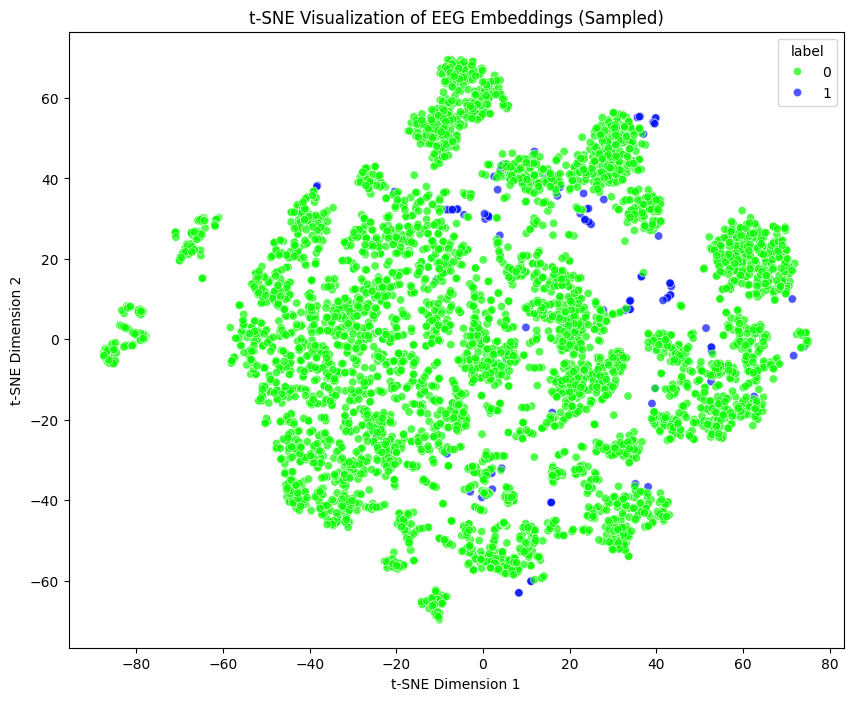

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# It's recommended to sample for t-SNE if the dataset is very large
# Let's take a stratified sample to ensure representation of both classes

# Combine embeddings and labels for sampling
df_embeddings_labels = pd.DataFrame({
    'embedding': list(all_embeddings),
    'label': df_windows['label'].values # Use original labels from df_windows
})

# Determine sample size for each class
num_seizure_samples = min(500, df_embeddings_labels[df_embeddings_labels['label'] == 1].shape[0])
num_non_seizure_samples = min(5000, df_embeddings_labels[df_embeddings_labels['label'] == 0].shape[0])

# Stratified sampling
sampled_seizure = df_embeddings_labels[df_embeddings_labels['label'] == 1].sample(n=num_seizure_samples, random_state=42)
sampled_non_seizure = df_embeddings_labels[df_embeddings_labels['label'] == 0].sample(n=num_non_seizure_samples, random_state=42)

sampled_df = pd.concat([sampled_seizure, sampled_non_seizure])

sampled_embeddings = np.vstack(sampled_df['embedding'].values)
sampled_labels = sampled_df['label'].values

print(f"Running t-SNE on {len(sampled_embeddings)} sampled embeddings...")

tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000, verbose=1)
tsne_results = tsne.fit_transform(sampled_embeddings)

# Create a DataFrame for plotting
tsne_df = pd.DataFrame(tsne_results, columns=['tsne-2d-one', 'tsne-2d-two'])
tsne_df['label'] = sampled_labels

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='tsne-2d-one', y='tsne-2d-two',
    hue='label',
    palette=sns.color_palette('hsv', 2),
    data=tsne_df,
    legend='full',
    alpha=0.7
)
plt.title('t-SNE Visualization of EEG Embeddings (Sampled)')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

### Evaluation Metrics for Seizure Classifier

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Put classifier in evaluation mode
classifier.eval()
encoder.eval()

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():
    for x, labels, _ in val_loader_clf:
        x, labels = x.to(DEVICE), labels.to(DEVICE).float()

        embeddings = encoder(x)
        logits = classifier(embeddings)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).long()

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

# Convert to numpy arrays
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

# Compute metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)

print(f"Classifier Evaluation on Validation Set:")
print(f"  Accuracy: {accuracy:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall: {recall:.4f}")
print(f"  F1-Score: {f1:.4f}")
print(f"  AUC: {auc:.4f}")

Classifier Evaluation on Validation Set:
  Accuracy: 0.9992
  Precision: 0.5882
  Recall: 0.5263
  F1-Score: 0.5556
  AUC: 0.9696


### Training Curves Plot

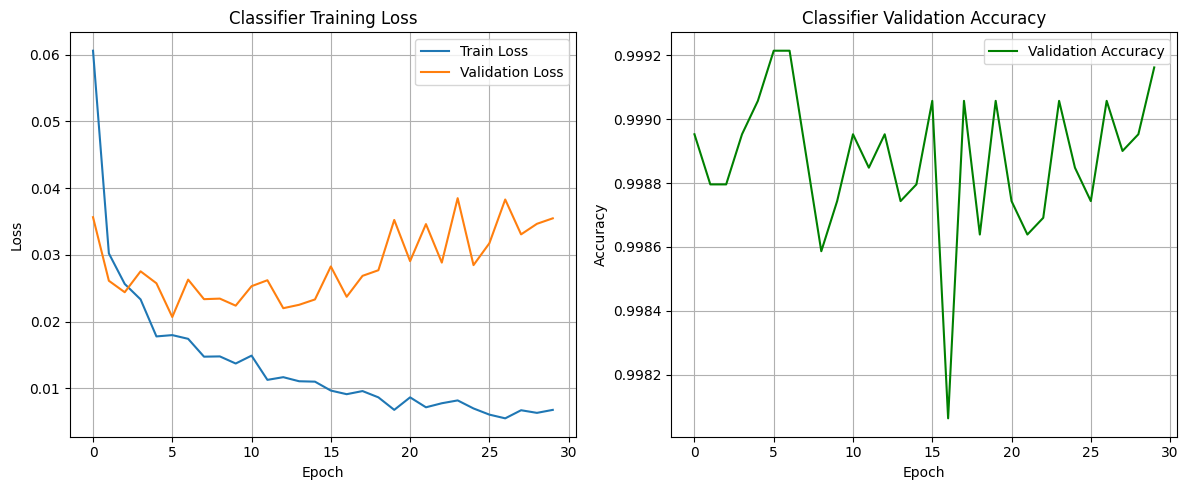

In [ ]:
import matplotlib.pyplot as plt

# Plot training history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(clf_history['train_loss'], label='Train Loss')
plt.plot(clf_history['val_loss'], label='Validation Loss')
plt.title('Classifier Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(clf_history['val_acc'], label='Validation Accuracy', color='green')
plt.title('Classifier Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
#here the loss values are plotted(since it takes a lot of time to train the model again and then plot)

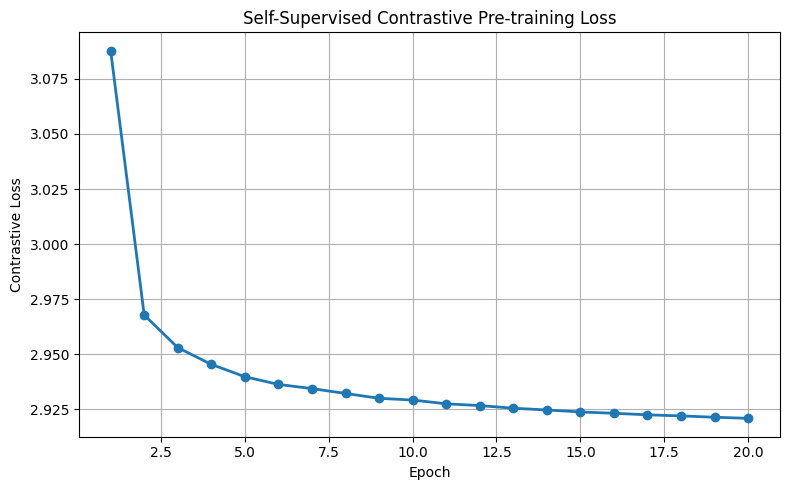

In [ ]:
import matplotlib.pyplot as plt

# Epochs and corresponding contrastive loss values
epochs = list(range(1, 21))
losses = [
    3.0878, 2.9678, 2.9530, 2.9454, 2.9398,
    2.9363, 2.9344, 2.9322, 2.9300, 2.9292,
    2.9275, 2.9267, 2.9255, 2.9247, 2.9238,
    2.9232, 2.9225, 2.9220, 2.9214, 2.9209
]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, losses, marker='o', linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Contrastive Loss")
plt.title("Self-Supervised Contrastive Pre-training Loss")
plt.grid(True)

# Optional: tighten layout for paper-quality figure
plt.tight_layout()

plt.show()
